# 09 · Event anatomy: the weather behind the heaviest winter rain days

**Question for this notebook.** When the heaviest winter rain falls over the UK and Ireland, what
weather pattern brings it, and how does that pattern develop over the preceding days? Do the
models produce their heaviest rain days through the **same** weather as the real world?

A model can get the *amount* of extreme rain right for the wrong reason. This notebook checks the
reason: the large-scale pressure pattern on and before the event days. It also looks at two
circulation features that matter for extremes: how active the passing storms are (storminess),
and how often high pressure sits over the UK for days on end (a simple blocking proxy).

**Data.** Winters (December–February) 1986–2014.
- Daily precipitation averaged over UK and Ireland land (the same land cells for every dataset).
- Daily sea-level pressure on the North Atlantic box at 1°.
- ERA5 (reanalysis), ICON-ESM-ER and IFS-FESOM2-SR. E-OBS rain days are paired with ERA5 pressure.

**Method.**
1. For each dataset, take the **30 wettest winter days** over UK and Ireland, at least 5 days
   apart so that one storm is counted once.
2. Average the pressure *anomaly* (difference from that dataset's own average winter day) over
   those 30 days, and over the 1, 2 and 3 days before them. This is called a **composite**.
3. Compare the model composites with ERA5's.

**Sections**
1. Setup
2. Findings
3. The events
4. The weather on the day
5. The days before
6. Numbers: where is the low, how strong is the flow?
7. Storminess
8. Persistent high pressure over the UK (blocking proxy)
9. Limitations
10. Open questions

## Background: the terms used in this notebook

| Term | What it means here |
|---|---|
| **Event** | One of the 30 wettest winter days over UK and Ireland land in a dataset. |
| **Composite** | The average over all events. Individual storms differ; their average shows what they have in common. |
| **Pressure anomaly** | Sea-level pressure minus that dataset's average winter value at that place. Blue: lower than usual (a low, a storm); orange: higher (a high). |
| **Lag** | Days before the event: lag −2 is two days before the wettest day. |
| **Westerly flow** | Wind from the west. In the northern hemisphere, wind blows with low pressure on its left, so lower pressure to the north than to the south means westerly wind. The pressure difference between 50°N and 60°N is used as a simple measure of its strength. |
| **Storminess** | How much pressure changes from one day to the next. Where storms pass often, pressure jumps up and down; the standard deviation of the daily change is high. |
| **Blocking** | A large, persistent high-pressure system that sits still for days and diverts storms. Long spells of high pressure over the UK are used here as a simple proxy. Such spells also bring stagnant air, which matters for air quality; that link is *not* analysed here. |

**How to read the maps.** All maps are pressure anomalies or differences. Blue = lower, orange =
higher, grey = no difference. All panels of a figure share one colour scale.

**Colours of the lines.** Dark grey ERA5, light grey E-OBS, blue ICON-ESM-ER, orange IFS-FESOM2-SR.

## 1. Setup

**What this cell does.** Loads the project code.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
from eerie_uk import climatology as clim, events as ev, extremes as ex, plotting, regions, store

pd.set_option('display.width', 220, 'display.float_format', '{:.2f}'.format)
NAME = plotting.SOURCE_LABELS
CIRCULATION = ['era5', 'icon-esm-er', 'ifs-fesom2-sr']       # datasets with daily pressure
RAIN = ['e-obs', 'era5', 'icon-esm-er', 'ifs-fesom2-sr']
PRESSURE_OF = {'e-obs': 'era5', 'era5': 'era5', 'icon-esm-er': 'icon-esm-er', 'ifs-fesom2-sr': 'ifs-fesom2-sr'}
WINTERS = ('1985-12-01', '2014-02-28')

**What this cell does.** Loads daily winter precipitation and averages it over UK and Ireland land.
The same land cells (land where E-OBS has data) are used for every dataset.

In [2]:
def winter(da):
    da = da.sel(time=slice(*WINTERS))
    return da.sel(time=da.time.dt.month.isin([12, 1, 2]))

pr = {d: winter(store.load(d, 'day', 'pr', 'nw_europe')) for d in RAIN}
grid = pr['era5']
pr['e-obs'] = regions.to_grid(pr['e-obs'], grid)
land = regions.land_mask(grid.lat, grid.lon)
common = land & pr['e-obs'].isel(time=0).notnull()
uk_rain = {d: clim.regional_mean(pr[d].where(common), 'uk_ireland') for d in RAIN}
pd.DataFrame([{'dataset': NAME[d], 'winter days': uk_rain[d].sizes['time'], 'mean (mm/day)': float(uk_rain[d].mean()),
               'wettest day (mm)': float(uk_rain[d].max())} for d in RAIN])

,dataset,winter days,mean (mm/day),wettest day (mm)
0,E-OBS,2617,3.21,19.29
1,ERA5,2617,2.88,17.42
2,ICON-ESM-ER,2617,5.19,21.47
3,IFS-FESOM2-SR,2617,3.49,17.98


**What this cell does.** Loads daily winter sea-level pressure (1° grid) and turns it into anomalies
from each dataset's own average winter day, 1986–2014.

In [3]:
psl = {d: winter(store.load(d, 'day', 'psl', 'north_atlantic')) for d in CIRCULATION}
anomaly = {d: psl[d] - psl[d].mean('time') for d in CIRCULATION}
pd.DataFrame([{'dataset': NAME[d], 'winter days': psl[d].sizes['time'], 'grid': f"{psl[d].sizes['lat']} x {psl[d].sizes['lon']}",
               'mean (hPa)': float(psl[d].mean()), 'units': psl[d].attrs.get('units')} for d in CIRCULATION])

,dataset,winter days,grid,mean (hPa),units
0,ERA5,2617,60 x 130,1013.01,hPa
1,ICON-ESM-ER,2617,60 x 130,1011.53,hPa
2,IFS-FESOM2-SR,2617,60 x 130,1014.34,hPa


## 2. Findings

Winters 1986–2014, the 30 wettest winter days over UK and Ireland land in each dataset. One member per model.

| | E-OBS events | ERA5 events | ICON-ESM-ER | IFS-FESOM2-SR |
|---|---|---|---|---|
| Mean rain on the 30 event days (UK and Ireland land) | 13.4 mm | 13.5 mm | 16.3 mm | 14.8 mm |
| Composite low on the event day: centre | 56°N 15°W | 54°N 10°W | 57°N 10°W | 56°N 13°W |
| Composite low: depth (anomaly) | −24.5 hPa | −26.7 hPa | −22.2 hPa | −22.0 hPa |
| Event pattern similarity to ERA5, event day | 0.96 | 1 | 0.95 | 0.94 |
| Event pattern similarity to ERA5, two days before | 0.94 | 1 | **0.72** | 0.85 |
| Storminess over UK and Ireland (hPa per day) | – | 8.3 | 9.7 (+17%) | 9.3 (+13%) |
| Persistent strong highs over the UK (days per winter) | – | 17.0 | 14.2 | 14.9 |

**What this means, in plain words**

1. **Heavy winter rain over the UK and Ireland comes with a deep low just north-west of the islands.** In the real world the composite low is centred over or just west of Ireland, about 25 hPa deeper than usual, with higher pressure to the south: strong, moist south-westerly flow onto the coast. A broad low is already visible over the Atlantic three days before.
2. **Both models produce their heaviest rain days through the same kind of weather.** On the event day their composite pattern matches ERA5's closely (pattern correlation 0.94–0.95), with the low in a similar place and only slightly shallower. The models are not getting heavy rain "for the wrong reason".
3. **The difference is in the build-up.** Two days before the event, IFS-FESOM2-SR's pattern still resembles ERA5's well (0.85), but ICON-ESM-ER's much less (0.72): its storms show less of a precursor over the Atlantic and appear more abruptly near the event. With 30 events this is an indication, not a firm result.
4. **Both models show enhanced synoptic storminess over the UK and the north-east Atlantic** (+13 to +17% variability of the day-to-day pressure change, a proxy; individual cyclones are not tracked). In ICON-ESM-ER the increase is concentrated over the north-east Atlantic, the UK and Scandinavia, with *less* activity off North America: the storminess maximum is shifted towards Europe. That is consistent with its too-strong westerlies (notebook 03) and its too-heavy rain (notebook 05).
5. **Persistent highs over the UK are slightly less frequent in both models** (about 14–15 days per winter in long strong-high spells, against 17 in ERA5), but the number of spells is similar. Unlike many older climate models, these two show no large blocking deficit by this simple measure.
6. **The event list itself depends on the reference.** Only 14 of E-OBS's 30 wettest days are also among ERA5's 30 (within a day), although both describe the same real winters. The composite *pattern* is almost the same for both lists (0.96), so the conclusions about weather patterns are robust to this; conclusions about individual events would not be.

**A measurement caveat.** The simple westerly index used in section 6 (pressure difference between 50°N and 60°N along 10°W) sits right across the composite low when the low is centred near 54°N, so it does not capture the flow well for ERA5's events. It is reported for completeness; the maps are the better guide.

**Answer to the question.** Both models bring their heaviest UK and Ireland winter rain with the same weather pattern as the real world: a deep low to the north-west. IFS-FESOM2-SR also reproduces the build-up over the preceding days; ICON-ESM-ER's storms develop with less warning. Both models show enhanced synoptic storminess over the UK (a day-to-day pressure-variability proxy), which fits their wet biases. These are exploratory results from one member each.

## 3. The events

**What this cell does.** Finds the 30 wettest winter days over UK and Ireland in each dataset, at
least 5 days apart, and summarises them: how wet they were and in which month they fell.

In [4]:
N = 30
dates = {d: ev.top_events(uk_rain[d], n=N, separation=5) for d in RAIN}
rows = []
for d in RAIN:
    amounts = uk_rain[d].sel(time=dates[d]).values
    months = pd.DatetimeIndex(dates[d]).month
    rows.append({'dataset': NAME[d], 'events': len(dates[d]), 'mean amount (mm)': amounts.mean(),
                 'smallest of the 30 (mm)': amounts.min(), 'largest (mm)': amounts.max(),
                 'December': int((months == 12).sum()), 'January': int((months == 1).sum()), 'February': int((months == 2).sum())})
pd.DataFrame(rows)

,dataset,events,mean amount (mm),smallest of the 30 (mm),largest (mm),December,January,February
0,E-OBS,30,13.38,11.41,19.29,15,10,5
1,ERA5,30,13.48,11.79,17.42,17,7,6
2,ICON-ESM-ER,30,16.30,14.63,21.47,11,10,9
3,IFS-FESOM2-SR,30,14.76,13.07,17.98,14,10,6


**Reading the table.** These amounts are averages over all UK and Ireland land, so they are much
smaller than what a single rain gauge records on the same day. ERA5 and E-OBS describe the same real
winters, so many of their 30 dates coincide; the models have their own weather.

**What this cell does.** Checks how many of the 30 real-world event days are the same in E-OBS and
ERA5 (within one day). This shows how much the event list itself depends on the reference.

In [5]:
def overlap(a, b, tolerance=1):
    return sum(any(abs((x - y).days) <= tolerance for y in b) for x in a)
print('E-OBS events that are also ERA5 events (within a day):', overlap(dates['e-obs'], dates['era5']), 'of', N)

E-OBS events that are also ERA5 events (within a day): 14 of 30


## 4. The weather on the day

**What this cell does.** Maps the average pressure anomaly on the event days (lag 0) for each
dataset. E-OBS events use ERA5 pressure.

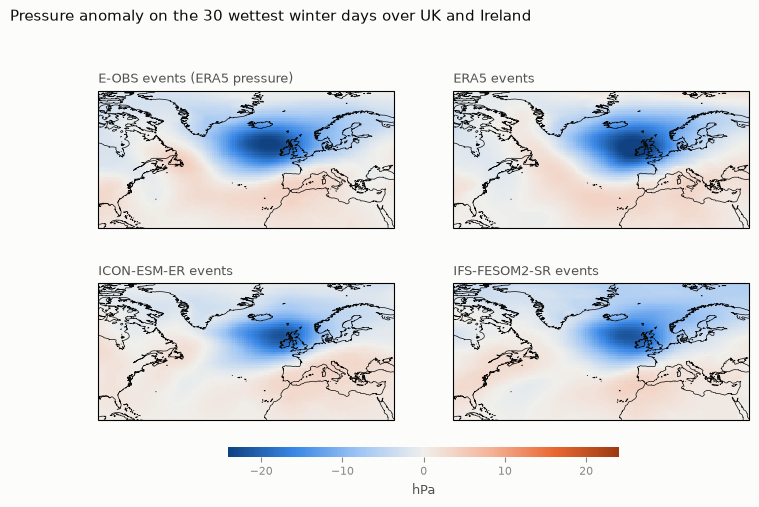

In [6]:
composites = {d: ev.lagged_composite(anomaly[PRESSURE_OF[d]], dates[d], lags=(-3, -2, -1, 0)) for d in RAIN}
labels = {'e-obs': 'E-OBS events (ERA5 pressure)', 'era5': 'ERA5 events', 'icon-esm-er': 'ICON-ESM-ER events', 'ifs-fesom2-sr': 'IFS-FESOM2-SR events'}
plotting.plot_field_panels({labels[d]: composites[d].sel(lag=0) for d in RAIN}, units='hPa', diverging=True, columns=2,
                           title='Pressure anomaly on the 30 wettest winter days over UK and Ireland');

**Figure 1.** The weather on a typical heavy-rain day. Blue: lower pressure than usual (the storm);
orange: higher. Heavy UK rain should come with a deep low to the north-west of the UK and higher
pressure to the south, which drives strong, moist westerly or south-westerly winds onto the coast.

## 5. The days before

**What this cell does.** Shows the same composite 3, 2 and 1 days before the events and on the day,
for ERA5 and both models: how the storm approaches.

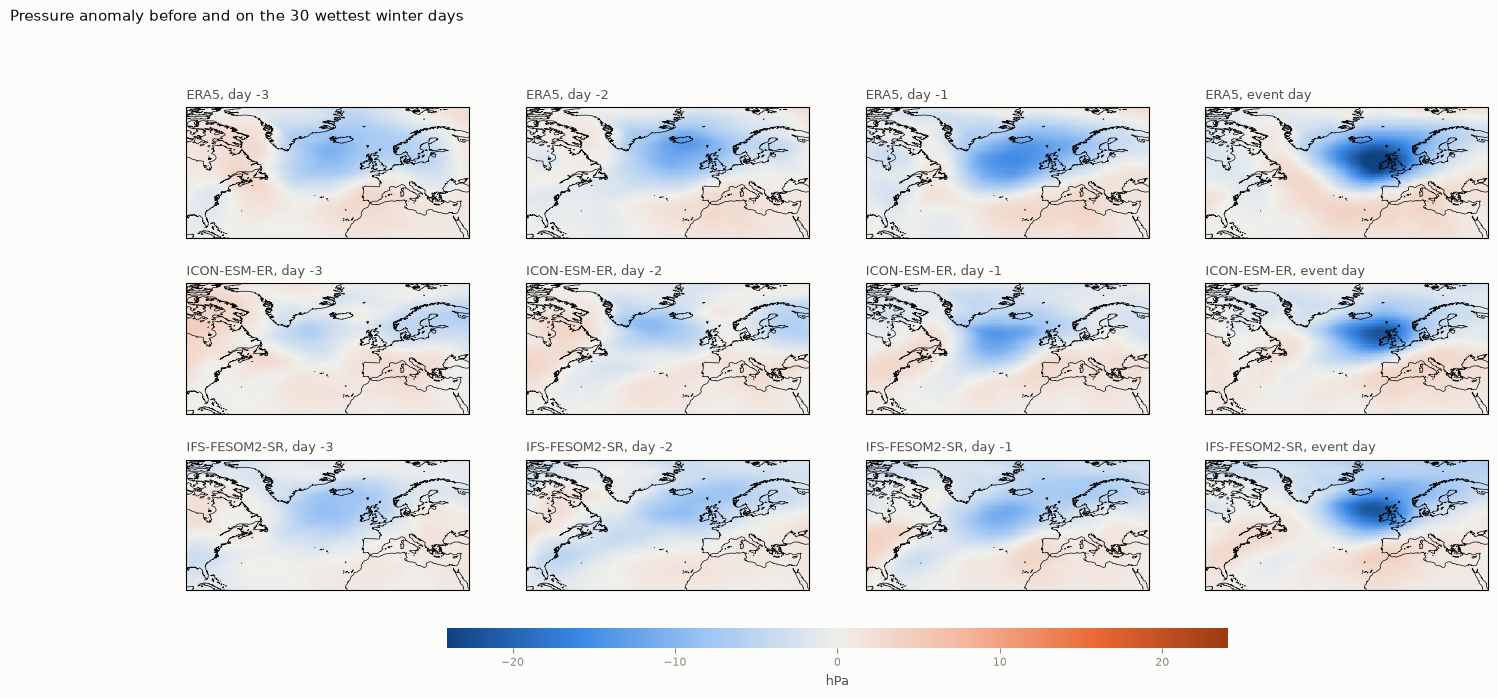

In [7]:
panels = {}
for d in CIRCULATION:
    for lag in (-3, -2, -1, 0):
        panels[f'{NAME[d]}, day {lag}' if lag else f'{NAME[d]}, event day'] = composites[d].sel(lag=lag)
plotting.plot_field_panels(panels, units='hPa', diverging=True, columns=4,
                           title='Pressure anomaly before and on the 30 wettest winter days');

**Figure 2.** Each row is one dataset, from three days before (left) to the event day (right).
In the real world (top row) the low typically moves in from the west across the Atlantic and
deepens. A model that brings its storms from a different direction, or forms them in place, would
show a different sequence.

## 6. Numbers: where is the low, how strong is the flow?

**What this cell does.** Puts numbers on Figures 1 and 2. For each dataset: where the composite low
is centred on the event day and how deep it is; the strength of the westerly flow over the UK on
event days (pressure at 50°N minus 60°N along 10°W, compared with an ordinary winter day); and how
similar the model's event pattern is to ERA5's (pattern correlation, at each lag).

In [8]:
def westerly(field):
    return float(field.sel(lat=50, lon=-10, method='nearest') - field.sel(lat=60, lon=-10, method='nearest'))
rows = []
for d in RAIN:
    day0 = composites[d].sel(lag=0)
    low = day0.where(day0 == day0.min(), drop=True)
    full = psl[PRESSURE_OF[d]]
    event_days = full.sel(time=pd.DatetimeIndex(dates[d])[pd.DatetimeIndex(dates[d]).isin(full.time.values)])
    rows.append({'events of': NAME[d], 'low centre lat': float(low.lat[0]), 'low centre lon': float(low.lon[0]),
                 'low depth (hPa anomaly)': float(day0.min()),
                 'westerly index on event days (hPa)': westerly(event_days.mean('time')),
                 'westerly index on an average winter day (hPa)': westerly(full.mean('time')),
                 **{f'pattern correlation with ERA5, day {lag}': clim.pattern_stats(composites[d].sel(lag=lag), composites['era5'].sel(lag=lag))['pattern correlation'] for lag in (-2, 0)}})
pd.DataFrame(rows)

,events of,low centre lat,low centre lon,low depth (hPa anomaly),westerly index on event days (hPa),westerly index on an average winter day (hPa),"pattern correlation with ERA5, day -2","pattern correlation with ERA5, day 0"
0,E-OBS,56.38,-14.62,-24.52,14.40,11.16,0.94,0.96
1,ERA5,54.38,-9.62,-26.71,10.78,11.16,1.00,1.00
2,ICON-ESM-ER,57.38,-9.62,-22.21,24.04,19.70,0.72,0.95
3,IFS-FESOM2-SR,56.38,-12.62,-21.97,15.74,12.53,0.85,0.94


**Reading the table.** A larger westerly index means a stronger pressure drop towards the north, so
stronger westerly winds over the UK. The difference between event days and an average day shows
how much heavy rain depends on unusually strong westerlies.

## 7. Storminess

**What this cell does.** Maps the standard deviation of the day-to-day change of pressure in
winter: where it is large, storms pass often and fast. This is a simple *proxy* for synoptic
storminess along the North Atlantic storm track; individual cyclones are not tracked.

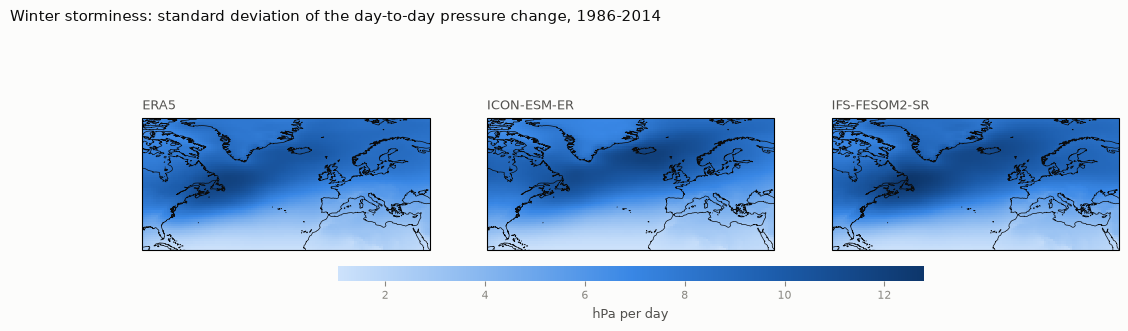

In [9]:
storminess = {d: ev.day_to_day_change(psl[d]) for d in CIRCULATION}
plotting.plot_field_panels({NAME[d]: storminess[d] for d in CIRCULATION}, units='hPa per day',
                           title='Winter storminess: standard deviation of the day-to-day pressure change, 1986-2014');

**Figure 3.** Storminess: the band of high values marks where Atlantic storms travel, typically from
Newfoundland towards Iceland and Norway.

**What this cell does.** Shows each model's storminess minus ERA5's, so storminess that is too
strong, too weak or displaced stands out, and summarises it over the UK.

,dataset,storminess over UK and Ireland (hPa/day),"storminess, whole North Atlantic box",pattern correlation with ERA5
0,ERA5,8.26,6.05,1.00
1,ICON-ESM-ER,9.66,5.94,0.98
2,IFS-FESOM2-SR,9.34,6.49,1.00


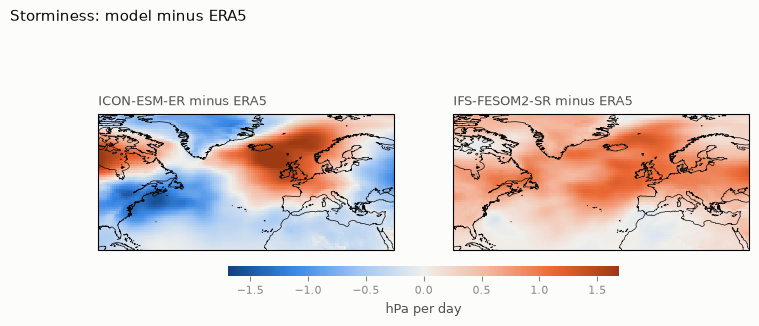

In [10]:
plotting.plot_field_panels({f'{NAME[m]} minus ERA5': storminess[m] - storminess['era5'] for m in CIRCULATION[1:]},
                           units='hPa per day', diverging=True, title='Storminess: model minus ERA5');
pd.DataFrame([{'dataset': NAME[d], 'storminess over UK and Ireland (hPa/day)': float(clim.regional_mean(storminess[d], 'uk_ireland')),
               'storminess, whole North Atlantic box': float(regions.area_mean(storminess[d])),
               'pattern correlation with ERA5': clim.pattern_stats(storminess[d], storminess['era5'])['pattern correlation']} for d in CIRCULATION])

**Figure 4.** Orange: storms more active than in ERA5; blue: less active.

## 8. Persistent high pressure over the UK (blocking proxy)

Long spells of high pressure over the UK bring dry, calm and, in winter, cold weather, and trap
pollution near the ground. They are the opposite situation to the rain events above.

**What this cell does.** Averages the daily pressure anomaly over the UK and Ireland box and counts
spells of at least 5 consecutive winter days with an anomaly above +10 hPa (a strong, persistent
high). The same fixed threshold is used for all datasets, so the counts are directly comparable.

In [11]:
THRESHOLD, LENGTH = 10.0, 5
rows = []
spell_panels = {}
for d in CIRCULATION:
    uk = clim.regional_mean(anomaly[d], 'uk_ireland')
    spells = []
    for year in range(1986, 2015):
        part = uk.sel(time=slice(f'{year - 1}-12-01', f'{year}-02-28'))
        spells += ev.persistent_episodes(part.values, THRESHOLD, LENGTH)
    rows.append({'dataset': NAME[d], 'spells in 29 winters': len(spells), 'per winter': len(spells) / 29,
                 'mean length (days)': float(np.mean(spells)) if spells else 0.0, 'longest (days)': max(spells) if spells else 0,
                 'days in such spells per winter': sum(spells) / 29,
                 'standard deviation of UK daily anomaly (hPa)': float(uk.std())})
pd.DataFrame(rows)

,dataset,spells in 29 winters,per winter,mean length (days),longest (days),days in such spells per winter,standard deviation of UK daily anomaly (hPa)
0,ERA5,52,1.79,9.48,23,17.00,14.34
1,ICON-ESM-ER,48,1.66,8.56,24,14.17,14.34
2,IFS-FESOM2-SR,48,1.66,8.98,20,14.86,14.59


**Reading the table.** A model with too few or too short spells has too little persistent high
pressure (too little blocking) over the UK; this is a long-standing weakness of climate models. The
last column shows how strongly UK pressure varies from day to day in each dataset.

## 9. Limitations

- **30 events per dataset** from 29 winters. Composites of 30 storms are reasonably stable, but
  details of individual panels are noisy.
- **Pressure only.** Moisture transport, fronts and winds aloft are not analysed; the jet stream
  itself would need upper-air data.
- **1° pressure grid** and daily means: the sharp structure of fronts is smoothed.
- **The blocking measure is a simple proxy** (a fixed pressure threshold over one box), not a
  standard blocking index, and the air-quality link is not analysed.
- **One member per model.**
- **Anomalies are relative to each dataset's own average winter,** so mean-state biases (notebook
  03) are removed; the question here is the *pattern* of the events.

## 10. Open questions

1. Is ICON-ESM-ER's weaker precursor two days before events a real difference in how its storms
   develop? Upper-air data (the jet stream) would show this more directly.
2. Does the enhanced storminess over the UK explain part of the models' wet biases? Cyclone
   tracking would show whether it means more storms, stronger storms or a shifted track.
3. How do the weather patterns behind summer heat extremes compare?